# P4 – Similar Songs

## What this part does

This notebook owns the **"geometry" models**: methods that treat every song as a point in feature space (one axis per feature) and reason about **distances** and **boundaries**.

In the app this is **Similar Songs**: pick any song and get the 5 songs that sound most like it, the classic "you might also like" recommender, built with **k-nearest neighbours (kNN)**. We compare two ways of measuring "similar" (Euclidean vs cosine). Then we use the same geometry for genre classification: a **kNN classifier** and a **Support Vector Machine (SVM)**. The questions: *how is "similar" measured, and how does an SVM separate genres?*

## Concepts in plain English

**k-nearest neighbours (kNN).** To find songs like song X, measure the distance from X to every other song and take the k closest. As a **classifier**, kNN predicts a song's genre by a **majority vote** of its k nearest training songs. kNN is a **lazy learner**: "training" just stores the songs; all the work (computing distances to every stored song) happens at prediction time, which is why it is slow for big datasets.

**Choosing k (bias–variance).** **Small k** (e.g. 1) follows every single neighbour, including noisy or mislabelled ones, so it **overfits** (high variance). **Large k** averages over many songs, including ones from other genres, so the decision becomes too smooth and **underfits** (high bias). We choose k by cross-validation.

**Distance metrics.**
- **Euclidean distance**: the straight-line gap between two points, √(Σ (xᵢ − yᵢ)²). Two songs are close if *every* feature value is close.
- **Cosine similarity**: the angle between two feature vectors, ignoring their length. Two songs are similar if they have the same *shape* or profile (which features are above or below average), even if one is more extreme. Cosine distance = 1 − cosine similarity.

**Why scaling is essential.** Distances add up squared differences across features. Unscaled, tempo differences (~10–50 BPM) would completely swamp danceability differences (~0.1), and the recommender would just find songs with similar tempo. After standard scaling every feature contributes fairly.

**Curse of dimensionality.** In many dimensions, points spread out and the distance to the nearest and to the farthest song become almost the same, so "nearest" means less. Adding weak or irrelevant features (like 11 one-hot key columns) makes distances noisier.

**Support Vector Machine (SVM).** For two genres, an SVM draws the boundary (a **hyperplane**: a line in 2D, a flat sheet in more dimensions) that leaves the **widest possible margin**, the empty gap between the boundary and the closest songs of each genre. The few songs that sit on the edge of the margin and "hold it in place" are the **support vectors**; all other songs could be removed without changing the boundary. A **soft margin** allows some songs on the wrong side; **C** sets how much each mistake costs: **large C** = few mistakes allowed (narrow margin, risk of overfitting); **small C** = wider margin, more tolerance (smoother, may underfit). For 6 genres, scikit-learn trains one SVM for **every pair of genres** (15 "one-vs-one" SVMs) and lets them vote.

**Kernel trick.** A straight boundary may not separate genres well. The **RBF kernel** lets the SVM draw **curved** boundaries by implicitly mapping songs into a much higher-dimensional space where a flat boundary works, without ever computing that space (it only needs similarities between pairs of songs). **gamma** controls how far one song's influence reaches: large gamma = very local, wiggly boundaries; small gamma = smooth ones.

## Setup

In [1]:
import sys, time, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_validate

from src import data, evaluate
from src.style import GENRE_COLORS, setup_notebook_style

np.random.seed(42)
setup_notebook_style()
pd.set_option("display.width", 160, "display.max_colwidth", 40, "display.precision", 3)
FIG = data.ROOT / "results" / "figures" / "p4_similar"
MODELS = data.ROOT / "models" / "p4_similar"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

songs, X_all = data.load_all_songs()
X_train, X_test, y_train, y_test, feature_names = data.load_splits()
ytr, yte = y_train["genre"], y_test["genre"]
A = data.AUDIO_FEATURES
print("All songs:", len(songs), "| recommender features:", A)

All songs: 4267 | recommender features: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']


## 1. The recommender: 5 nearest songs
The recommender uses **all 4,267 songs** (no labels are involved, so there is no train/test issue), scaled with the training-set scaler. It uses the **10 continuous audio features**: section 3 shows that adding the one-hot key columns makes recommendations worse.

`similar_songs()` finds the k nearest songs to a given song with either metric.

In [2]:
knn_models = {m: NearestNeighbors(n_neighbors=6, metric=m, algorithm="brute").fit(X_all[A]) for m in ["euclidean", "cosine"]}

def similar_songs(track_index, k=5, metric="euclidean"):
    """Return the k songs most similar to song `track_index` (a song_id), excluding itself."""
    dist, idx = knn_models[metric].kneighbors(X_all.loc[[track_index], A], n_neighbors=k + 1)
    ids = [songs.index[i] for i in idx[0] if songs.index[i] != track_index][:k]
    d = [dd for i, dd in zip(idx[0], dist[0]) if songs.index[i] != track_index][:k]
    out = songs.loc[ids, ["track_name", "artists", "track_genre"]].copy()
    out["distance"] = np.round(d, 3)
    return out.reset_index()

def show(name, artist_part):
    sid = songs.index[(songs.track_name == name) & songs.artists.str.contains(artist_part, regex=False)][0]
    s = songs.loc[sid]
    print(f"Seed song: {s.track_name} – {s.artists}  [{s.track_genre}]")
    both = pd.concat({"Euclidean": similar_songs(sid, 5, "euclidean")[["track_name", "artists", "track_genre"]],
                      "Cosine": similar_songs(sid, 5, "cosine")[["track_name", "artists", "track_genre"]]}, axis=1)
    display(both)
    return sid

print("similar_songs() is ready. Three well-known example songs follow.")

similar_songs() is ready. Three well-known example songs follow.


### Example 1: a heavy-metal song

In [3]:
sid_metal = show("One Night in Tokyo", "Beast In Black")

Seed song: One Night in Tokyo – Beast In Black  [heavy-metal]


Euclidean                                                 Cosine                             
                 track_name         artists  track_genre                track_name         artists  track_genre
0      Tribute to B.B. King           Pappo  heavy-metal      Tribute to B.B. King           Pappo  heavy-metal
1  De Pismanta A Bauchaceta   Ricardo Iorio  heavy-metal  De Pismanta A Bauchaceta   Ricardo Iorio  heavy-metal
2  De Pismanta a Baucacheta       Hermetica  heavy-metal         Veri valuu maahan  Kotiteollisuus  heavy-metal
3         Veri valuu maahan  Kotiteollisuus  heavy-metal  De Pismanta a Baucacheta       Hermetica  heavy-metal
4                    Garras          Horcas  heavy-metal                    Garras          Horcas  heavy-metal

This shows that for a fast, loud power-metal song **all 5 recommendations are heavy-metal** with both metrics, and the two lists contain the same songs in a slightly different order. Heavy-metal sits in its own corner of feature space (very high energy, almost no acousticness), so its neighbours are easy to find.

### Example 2: a classical piece

In [4]:
sid_classical = show("River Flows In You", "Yiruma")

Seed song: River Flows In You – Yiruma  [classical]


Euclidean                                                                                        Cosine  \
                                track_name                                  artists track_genre                               track_name   
0  Suite for Solo Cello No. 1 in G Majo...    Johann Sebastian Bach;Göran Söllscher   classical  Suite for Solo Cello No. 1 in G Majo...   
1  2 Arabesques, L. 66: I. Andantino co...             Claude Debussy;Michel Béroff   classical  2 Arabesques, L. 66: I. Andantino co...   
2                     Rue des trois frères                       Fabrizio Paterlini   classical  8 Slavonic Dances, Op. 46, B.83 - Fo...   
3  8 Slavonic Dances, Op. 46, B.83 - Fo...  Antonín Dvořák;Katia Labèque;Mariell...   classical                     Rue des trois frères   
4                                Ouroboros                    Dominique Charpentier   classical                                Ouroboros   

                                                        
                                   artists track_genre  
0    Johann Sebastian Bach;Göran Söllscher   classical  
1             Claude Debussy;Michel Béroff   classical  
2  Antonín Dvořák;Katia Labèque;Mariell...   classical  
3                       Fabrizio Paterlini   classical  
4                    Dominique Charpentier   classical

This shows that a gentle solo-piano piece gets **5 classical neighbours** (Bach, Debussy, Dvořák and modern piano composers) with both metrics: quiet, acoustic, instrumental music. Euclidean and cosine agree on the same five songs, only ranks 3 and 4 swap.

### Example 3: a hip-hop song

In [5]:
sid_hiphop = show("Without Me", "Eminem")

Seed song: Without Me – Eminem  [hip-hop]


Euclidean                                                                              Cosine                                            
            track_name                                  artists track_genre                     track_name                         artists track_genre
0             Superman                          Eminem;Dina Rae     hip-hop            The Real Slim Shady                          Eminem     hip-hop
1            All Black           Raftaar;Sukh-E Muzical Doctorz     hip-hop                      All Black  Raftaar;Sukh-E Muzical Doctorz     hip-hop
2              Pam Pam                           Wisin & Yandel     hip-hop                       Superman                 Eminem;Dina Rae     hip-hop
3           Saiyaan Ji  Yo Yo Honey Singh;Neha Kakkar;Nushrr...     hip-hop  Rather Be (feat. Jess Glynne)        Clean Bandit;Jess Glynne         edm
4  The Real Slim Shady                                   Eminem     hip-hop                        Pam Pam                  Wisin & Yandel     hip-hop

This shows the recommender picks up **two other Eminem songs** ("Superman", "The Real Slim Shady") with no knowledge of the artist, purely from sound. Here the metrics differ: Euclidean gives 5 hip-hop songs, while cosine swaps one in for an edm song ("Rather Be"). Cosine only cares about the *shape* of the feature profile (danceable, energetic, speechy relative to average) and ignores how extreme it is, so it can match songs that have the same profile at a different intensity.

## 2. How good are the recommendations? Share of top-5 neighbours with the same genre
A simple quality check: for every song, what share of its 5 nearest neighbours have the same genre? We average over all 4,267 songs. (Random recommendations would give about 18%, the chance that a random song shares the genre.)

In [6]:
def same_genre_share(features, metric, k=5):
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric, algorithm="brute").fit(X_all[features])
    idx = nn.kneighbors(X_all[features], return_distance=False)[:, 1:]     # drop the song itself
    g = songs.track_genre.to_numpy(dtype=str)
    return (g[idx] == g[:, None]).mean()

chance = (songs.track_genre.value_counts(normalize=True) ** 2).sum()
share = pd.DataFrame({m: {"10 audio features": same_genre_share(A, m), "all 26 features (incl. one-hot key)": same_genre_share(feature_names, m)}
                      for m in ["euclidean", "cosine"]})
print(f"Chance level (random recommendations): {chance:.1%}")
for m in ["euclidean", "cosine"]:
    evaluate.log_score("P4 Similar Songs", f"kNN recommender ({m})", "recommender", {"same_genre_top5": share.loc["10 audio features", m]})
share.map(lambda v: f"{v:.1%}")

Chance level (random recommendations): 17.5%


,euclidean,cosine
10 audio features,61.5%,62.4%
all 26 features (incl. one-hot key),53.7%,54.5%


This shows that **about 62% of a song's 5 recommendations share its genre** (Euclidean 61.5%, cosine 62.4%), against 17.5% for random picks, so the recommender clearly finds musically related songs. Cosine is very slightly better. The second row is a small **curse-of-dimensionality** demonstration: adding the 16 one-hot key/time-signature columns *drops* the share to about 54%, because those columns add distance between songs that sound alike but are in different keys. That is why the recommender uses the 10 audio features.

## 3. Why scaling matters: the recommender without scaling
Let's see what happens to the same check if we skip scaling.

In [7]:
raw_feats = songs[A]
nn_raw = NearestNeighbors(n_neighbors=6).fit(raw_feats)
idx = nn_raw.kneighbors(raw_feats, return_distance=False)[:, 1:]
g = songs.track_genre.to_numpy(dtype=str)
print(f"Same-genre share WITHOUT scaling: {(g[idx] == g[:, None]).mean():.1%}   (with scaling: {share.loc['10 audio features', 'euclidean']:.1%})")
print("\nFeature spreads before scaling (std):")
print(raw_feats.std().round(3).sort_values(ascending=False).to_string())

Same-genre share WITHOUT scaling: 27.0%   (with scaling: 61.5%)

Feature spreads before scaling (std):
duration_ms         121527.760
tempo                   29.758
loudness                 6.874
acousticness             0.380
instrumentalness         0.318
energy                   0.294
valence                  0.229
liveness                 0.176
danceability             0.175
speechiness              0.071


This shows why scaling is essential: **without scaling only 27% of neighbours share the genre** (vs 61.5% with scaling). Unscaled, duration_ms has a spread of about 120,000 while speechiness has 0.07, so the "nearest" songs are simply the ones with the most similar length, and the other features are ignored.

## 4. kNN classifier for genre: choosing k by cross-validation
For each k from 1 to 25 (odd values, so votes rarely tie) we measure **5-fold cross-validated accuracy on the training set**, and also accuracy on the training songs themselves to show overfitting. We do this for both feature sets.

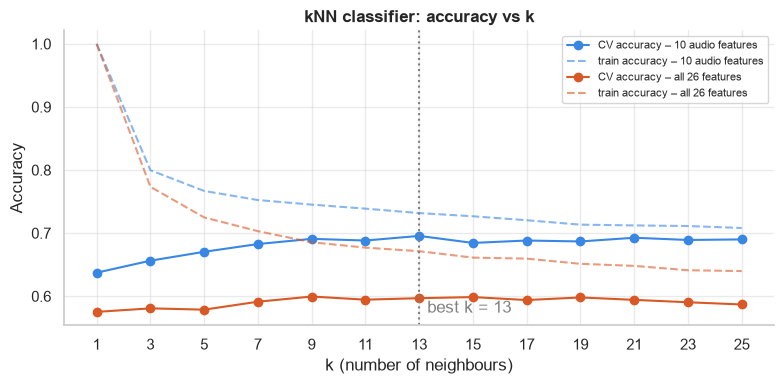

Best: k = 13 with 10 audio features (CV accuracy 0.696)


In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
ks = list(range(1, 26, 2))
rows = []
for fs_name, fs in [("10 audio features", A), ("all 26 features", feature_names)]:
    for k in ks:
        r = cross_validate(KNeighborsClassifier(n_neighbors=k), X_train[fs], ytr, cv=cv, return_train_score=True)
        rows.append({"features": fs_name, "k": k, "CV accuracy": r["test_score"].mean(), "train accuracy": r["train_score"].mean()})
kcurve = pd.DataFrame(rows)
best_row = kcurve.loc[kcurve["CV accuracy"].idxmax()]
BEST_K, BEST_FS_NAME = int(best_row.k), best_row.features
KNN_FEATURES = A if BEST_FS_NAME == "10 audio features" else feature_names

fig, ax = plt.subplots(figsize=(8, 4))
for fs_name, color in [("10 audio features", "#3987e5"), ("all 26 features", "#d95926")]:
    d = kcurve[kcurve.features == fs_name]
    ax.plot(d.k, d["CV accuracy"], marker="o", color=color, label=f"CV accuracy – {fs_name}")
    ax.plot(d.k, d["train accuracy"], ls="--", color=color, alpha=.6, label=f"train accuracy – {fs_name}")
ax.axvline(BEST_K, color="gray", ls=":"); ax.text(BEST_K + .3, ax.get_ylim()[0] + .02, f"best k = {BEST_K}", color="gray")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("Accuracy"); ax.set_xticks(ks)
ax.set_title("kNN classifier: accuracy vs k"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "knn_accuracy_vs_k.png", dpi=120); plt.show()
print(f"Best: k = {BEST_K} with {BEST_FS_NAME} (CV accuracy {best_row['CV accuracy']:.3f})")

This shows the bias–variance trade-off of k. At **k = 1, training accuracy is 100%** (each song's nearest neighbour is itself) but CV accuracy is the lowest: overfitting. As k grows, the gap closes and CV accuracy rises, peaking at **k = 13 with the 10 audio features (69.6%)**, then flattening or slowly falling as votes include more songs from other genres. Again, the 26-feature version is worse at every k: kNN suffers most from irrelevant dimensions.

In [9]:
knn = KNeighborsClassifier(n_neighbors=BEST_K).fit(X_train[KNN_FEATURES], ytr)
knn_met = evaluate.classification_metrics(yte, knn.predict(X_test[KNN_FEATURES]))
evaluate.log_score("P4 Similar Songs", f"kNN classifier (k={BEST_K})", "genre", knn_met)
print(f"kNN (k={BEST_K}) test accuracy {knn_met['accuracy']:.3f}, macro F1 {knn_met['macro_f1']:.3f}")

kNN (k=13) test accuracy 0.701, macro F1 0.671


## 5. SVM for genre: linear vs RBF kernel
We tune C (and gamma for RBF) with 5-fold cross-validation on the training set, and time it. All 26 features are used (SVMs cope well with extra weak features).

In [10]:
t0 = time.time()
svm_lin = GridSearchCV(SVC(kernel="linear"), {"C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, ytr)
t_lin = time.time() - t0
t0 = time.time()
svm_rbf = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.03, 0.1, 0.3]},
                       cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, ytr)
t_rbf = time.time() - t0
print(f"Linear SVM: best C = {svm_lin.best_params_['C']}, CV accuracy {svm_lin.best_score_:.3f}, tuning took {t_lin:.1f} s")
print(f"RBF SVM: best {svm_rbf.best_params_}, CV accuracy {svm_rbf.best_score_:.3f}, tuning took {t_rbf:.1f} s")

Linear SVM: best C = 1, CV accuracy 0.720, tuning took 6.3 s
RBF SVM: best {'C': 10, 'gamma': 0.01}, CV accuracy 0.718, tuning took 10.0 s


### Effect of C
CV accuracy as C grows, for the linear SVM and for the RBF SVM (at its best gamma).

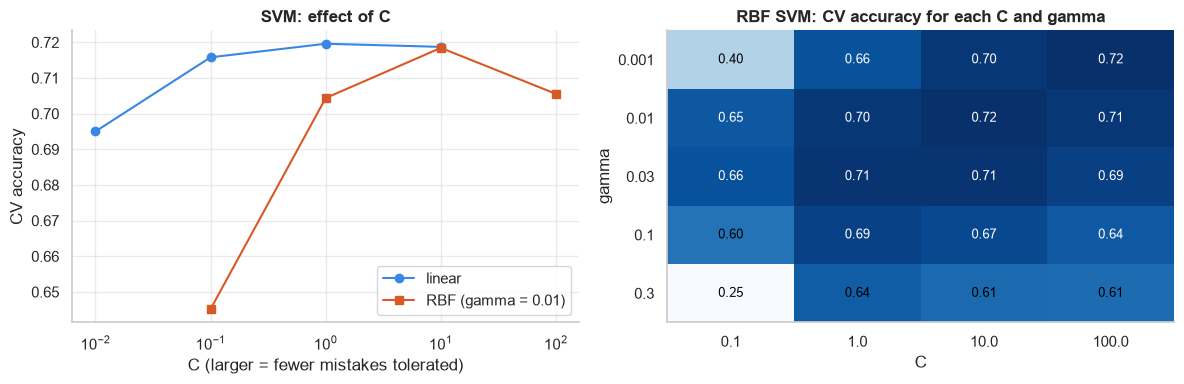

In [11]:
lin_res = pd.DataFrame(svm_lin.cv_results_)
rbf_res = pd.DataFrame(svm_rbf.cv_results_)
rbf_best_g = rbf_res[rbf_res.param_gamma == svm_rbf.best_params_["gamma"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lin_res.param_C.astype(float), lin_res.mean_test_score, marker="o", color="#3987e5", label="linear")
axes[0].plot(rbf_best_g.param_C.astype(float), rbf_best_g.mean_test_score, marker="s", color="#d95926",
             label=f"RBF (gamma = {svm_rbf.best_params_['gamma']})")
axes[0].set_xscale("log"); axes[0].set_xlabel("C (larger = fewer mistakes tolerated)"); axes[0].set_ylabel("CV accuracy")
axes[0].set_title("SVM: effect of C"); axes[0].legend()
pivot = rbf_res.pivot_table(index="param_gamma", columns="param_C", values="mean_test_score")
im = axes[1].imshow(pivot.values, cmap="Blues", aspect="auto"); axes[1].grid(False)
axes[1].set_xticks(range(len(pivot.columns)), pivot.columns); axes[1].set_yticks(range(len(pivot.index)), pivot.index)
axes[1].set_xlabel("C"); axes[1].set_ylabel("gamma"); axes[1].set_title("RBF SVM: CV accuracy for each C and gamma")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        axes[1].text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if pivot.values[i, j] > pivot.values.mean() else "black")
plt.tight_layout(); plt.savefig(FIG / "svm_effect_of_C.png", dpi=120); plt.show()

This shows that very **small C (0.01–0.1) underfits**: too many mistakes are tolerated and the margin is too wide. The linear SVM peaks at C = 1 (72.0% CV). For the RBF kernel the heatmap shows the interplay: a small gamma (0.01, smooth boundaries) with C = 10 is best (71.8%); a large gamma (0.3) gives wiggly boundaries that overfit and drop accuracy, whatever C is. The best linear and RBF models are practically tied, which says genre boundaries in our data are close to linear.

### Support vectors
How many training songs end up as support vectors? We refit the RBF SVM with small, medium and large C.

In [12]:
g_best = svm_rbf.best_params_["gamma"]
sv = []
for C in [0.1, 1, 10, 100]:
    m = SVC(kernel="rbf", C=C, gamma=g_best).fit(X_train, ytr)
    sv.append({"C": C, "support vectors": int(m.n_support_.sum()), "share of training songs": m.n_support_.sum() / len(X_train),
               "train accuracy": m.score(X_train, ytr)})
pd.DataFrame(sv).set_index("C").round(3)

,support vectors,share of training songs,train accuracy
C,,,
0.1,2919,0.855,0.669
1.0,2425,0.711,0.740
10.0,2125,0.623,0.789
100.0,1986,0.582,0.867


This shows that with **small C most songs become support vectors** (85% at C = 0.1): the wide, soft margin contains lots of songs. Raising C narrows the margin, so fewer songs are support vectors (58% at C = 100) and training accuracy rises (67% → 87%) while the CV accuracy above stops improving after C = 10: the model starts fitting the training songs too closely. Many support vectors overall tells us the genres overlap a lot.

### Test-set results for both SVMs

In [13]:
svm_rows = {}
for name, gs in [("SVM (linear)", svm_lin), ("SVM (RBF)", svm_rbf)]:
    met = evaluate.classification_metrics(yte, gs.best_estimator_.predict(X_test))
    evaluate.log_score("P4 Similar Songs", name, "genre", met)
    svm_rows[name] = met
svm_rows[f"kNN classifier (k={BEST_K})"] = knn_met
test_tab = pd.DataFrame(svm_rows).T[["accuracy", "macro_f1"]]
test_tab.round(3)

,accuracy,macro_f1
SVM (linear),0.725,0.697
SVM (RBF),0.714,0.684
kNN classifier (k=13),0.701,0.671


This shows the **linear SVM is the best genre model so far: 72.5% accuracy, 0.697 macro F1** on the test set, slightly ahead of the RBF SVM (71.4%) and kNN (70.1%), and of P3's logistic regression (71.5%). The differences are small (one or two points, i.e. about 10–20 test songs); P6 checks with bootstrap intervals whether they are real.

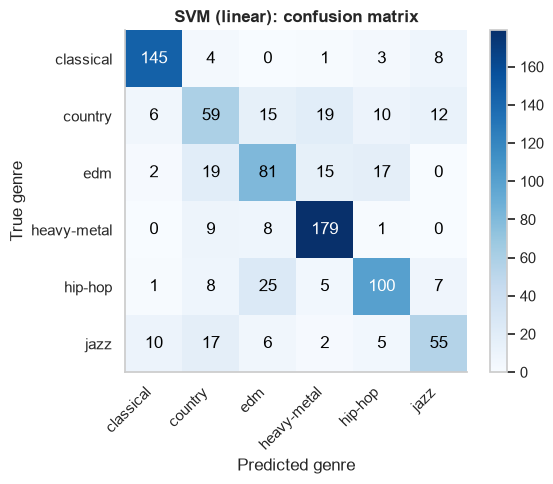

In [14]:
best_svm_name = max(["SVM (linear)", "SVM (RBF)"], key=lambda n: (svm_lin if n == "SVM (linear)" else svm_rbf).best_score_)
best_svm = (svm_lin if best_svm_name == "SVM (linear)" else svm_rbf).best_estimator_
evaluate.plot_confusion_matrix(yte, best_svm.predict(X_test), data.GENRES, f"{best_svm_name}: confusion matrix",
                               FIG / "cm_svm.png")
plt.show()
evaluate.plot_confusion_matrix(yte, knn.predict(X_test[KNN_FEATURES]), data.GENRES, f"kNN (k={BEST_K}): confusion matrix",
                               FIG / "cm_knn.png"); plt.close()

This shows the same pattern as P3's models: heavy-metal and classical are recognised very well, and most errors are **hip-hop ↔ edm** and **jazz ↔ country**. A better boundary-drawing method does not fix overlaps that come from the songs themselves.

## 6. Save for the app
- `recommender.joblib`: both NearestNeighbors models and the feature list.
- `neighbours.csv`: the 5 nearest songs of every song for both metrics (pre-computed so the app is instant).
- `svm_best.joblib`, `knn_best.joblib`: best genre classifiers (chosen by CV).

In [15]:
joblib.dump({"models": knn_models, "features": A}, MODELS / "recommender.joblib")
rows = []
for metric, nn in knn_models.items():
    dist, idx = nn.kneighbors(X_all[A], n_neighbors=6)
    for i, sid in enumerate(songs.index):
        nbrs = [(songs.index[j], d) for j, d in zip(idx[i], dist[i]) if songs.index[j] != sid][:5]
        rows += [{"song_id": sid, "metric": metric, "rank": r + 1, "neighbour_id": n, "distance": round(d, 4)}
                 for r, (n, d) in enumerate(nbrs)]
pd.DataFrame(rows).to_csv(MODELS / "neighbours.csv", index=False)
joblib.dump({"model": best_svm, "name": best_svm_name, "features": feature_names,
             "params": (svm_lin if best_svm_name == "SVM (linear)" else svm_rbf).best_params_}, MODELS / "svm_best.joblib")
joblib.dump({"model": knn, "name": f"kNN classifier (k={BEST_K})", "features": KNN_FEATURES}, MODELS / "knn_best.joblib")
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['knn_best.joblib', 'neighbours.csv', 'recommender.joblib', 'svm_best.joblib']


## Results summary

| Model / check | Setting | Result (test set) |
|---|---|---|
| Recommender: top-5 same genre (Euclidean) | 10 audio features | **61.5%** (chance 17.5%) |
| Recommender: top-5 same genre (cosine) | 10 audio features | **62.4%** |
| Recommender without scaling | Euclidean | 27.0% |
| kNN classifier | k = 13, 10 audio features | accuracy 0.701, macro F1 0.671 |
| SVM (linear) | C = 1 | **accuracy 0.725, macro F1 0.697** |
| SVM (RBF) | C = 10, gamma = 0.01 | accuracy 0.714, macro F1 0.684 |

**Takeaways**
- The recommender finds musically sensible songs (e.g. two other Eminem songs for "Without Me") and 62% of recommendations share the seed's genre.
- **Scaling is essential**: without it, the recommender just matches song length (27%).
- Extra one-hot columns hurt distance-based methods (curse of dimensionality), so the recommender and kNN use the 10 audio features.
- k = 1 overfits (100% train accuracy); k = 13 balances bias and variance.
- Linear and RBF SVMs tie in cross-validation, so the genre boundaries are nearly linear; the linear SVM is the best genre model so far.

## Questions you may be asked

**1. Why is kNN called a lazy learner? What is slow about it?**
It does no work when "training": it just stores all the training songs. Every prediction then has to compute the distance from the new song to *every* stored song and sort them, so prediction time grows with the size of the dataset (fine for our 4,267 songs, slow for millions without special index structures).

**2. How does k affect bias and variance?**
Small k = low bias, high variance: the prediction follows very few songs, so one odd neighbour can flip it (k = 1 gets 100% on training songs but lower CV accuracy: overfitting). Large k = high bias, low variance: the vote averages over many songs, including songs from other genres, so decisions become too smooth. Our CV curve peaks at k = 13.

**3. What is a support vector? What happens if you remove a non-support-vector song?**
Support vectors are the training songs that lie on the edge of the margin or inside it (including misclassified ones): they alone determine where the boundary goes. If you remove any other song (one comfortably on the correct side, outside the margin) and retrain, the boundary does not change at all.

**4. What does a large vs small C do?**
C is the price of each training mistake. Large C: mistakes are expensive, so the SVM squeezes the margin to classify almost every training song correctly (fewer support vectors, higher training accuracy: 87% at C = 100), which risks overfitting. Small C: mistakes are cheap, so it keeps a wide, smooth margin and accepts some errors (85% of songs are support vectors at C = 0.1), which can underfit. Cross-validation picked C = 1 (linear) and C = 10 (RBF).

**5. Explain the kernel trick in one sentence.**
The kernel trick lets an SVM find a curved boundary by computing similarities between songs as if they had been mapped into a much higher-dimensional space where a flat boundary works, without ever actually computing that space.